In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("student_dropout_cleaned.csv")
df = pd.read_csv(DATA_PATH)
df = df[df['target'] != 'Enrolled'].reset_index(drop=True) # Filter out 'Enrolled' class
df.head()


print(df.shape)
print(df.head())

(3630, 37)
   marital_status  application_mode  application_order  course  \
0               1                17                  5     171   
1               1                15                  1    9254   
2               1                 1                  5    9070   
3               1                17                  2    9773   
4               2                39                  1    8014   

   daytimeevening_attendance  previous_qualification  \
0                          1                       1   
1                          1                       1   
2                          1                       1   
3                          1                       1   
4                          0                       1   

   previous_qualification_grade  nacionality  mothers_qualification  \
0                         122.0            1                     19   
1                         160.0            1                      1   
2                         122.0           

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3630 entries, 0 to 3629
Data columns (total 37 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   marital_status                                3630 non-null   int64  
 1   application_mode                              3630 non-null   int64  
 2   application_order                             3630 non-null   int64  
 3   course                                        3630 non-null   int64  
 4   daytimeevening_attendance                     3630 non-null   int64  
 5   previous_qualification                        3630 non-null   int64  
 6   previous_qualification_grade                  3630 non-null   float64
 7   nacionality                                   3630 non-null   int64  
 8   mothers_qualification                         3630 non-null   int64  
 9   fathers_qualification                         3630 non-null   i

In [3]:
df.describe()

,marital_status,application_mode,application_order,course,daytimeevening_attendance,previous_qualification,previous_qualification_grade,nacionality,mothers_qualification,fathers_qualification,...,curricular_units_1st_sem_without_evaluations,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp
count,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,...,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000,3630.000000
mean,1.184298,18.421763,1.750138,8853.980992,0.887603,4.532231,132.920606,1.828099,19.986226,22.571625,...,0.128926,0.581818,6.296419,7.763085,4.518457,10.036155,0.142149,11.630358,1.231598,-0.009256
std,0.613009,17.358595,1.333831,2068.760082,0.315897,10.024134,13.238373,6.667614,15.585278,15.275453,...,0.679111,2.022688,2.263020,3.964163,3.162376,5.481742,0.747670,2.667652,1.384911,2.259986
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.517857,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9254.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.333333,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.500000,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,6.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [4]:
df.isnull().sum()

,0
marital_status,0
application_mode,0
application_order,0
course,0
daytimeevening_attendance,0
previous_qualification,0
previous_qualification_grade,0
nacionality,0
mothers_qualification,0
fathers_qualification,0


In [5]:
print(df.isnull().sum().sum())

0


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
print(df["target"].value_counts())

target
Graduate    2209
Dropout     1421
Name: count, dtype: int64


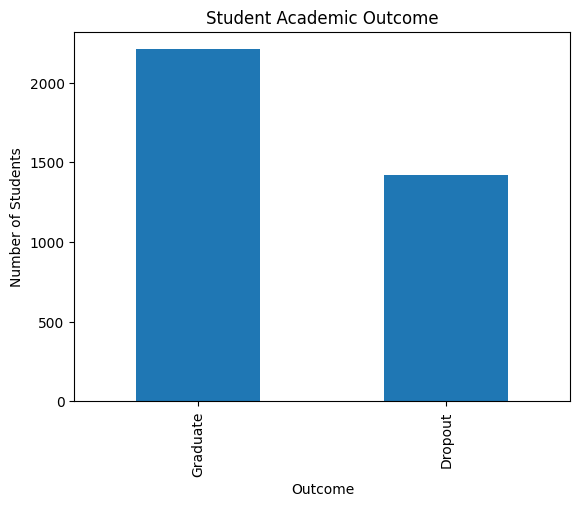

In [8]:
df["target"].value_counts().plot(kind="bar")

plt.title("Student Academic Outcome")
plt.xlabel("Outcome")
plt.ylabel("Number of Students")
plt.show()

In [9]:
categorical_columns = df.select_dtypes(include=["object"]).columns

print(categorical_columns)

Index(['target'], dtype='object')


In [10]:
for column in df.columns:
    print(column, ":", df[column].nunique())

marital_status : 6
application_mode : 18
application_order : 7
course : 17
daytimeevening_attendance : 2
previous_qualification : 17
previous_qualification_grade : 101
nacionality : 19
mothers_qualification : 29
fathers_qualification : 34
mothers_occupation : 29
fathers_occupation : 42
admission_grade : 602
displaced : 2
educational_special_needs : 2
debtor : 2
tuition_fees_up_to_date : 2
gender : 2
scholarship_holder : 2
age_at_enrollment : 46
international : 2
curricular_units_1st_sem_credited : 21
curricular_units_1st_sem_enrolled : 23
curricular_units_1st_sem_evaluations : 35
curricular_units_1st_sem_approved : 23
curricular_units_1st_sem_grade : 752
curricular_units_1st_sem_without_evaluations : 11
curricular_units_2nd_sem_credited : 19
curricular_units_2nd_sem_enrolled : 22
curricular_units_2nd_sem_evaluations : 29
curricular_units_2nd_sem_approved : 20
curricular_units_2nd_sem_grade : 724
curricular_units_2nd_sem_without_evaluations : 10
unemployment_rate : 10
inflation_rate : 9

4. Age vs target

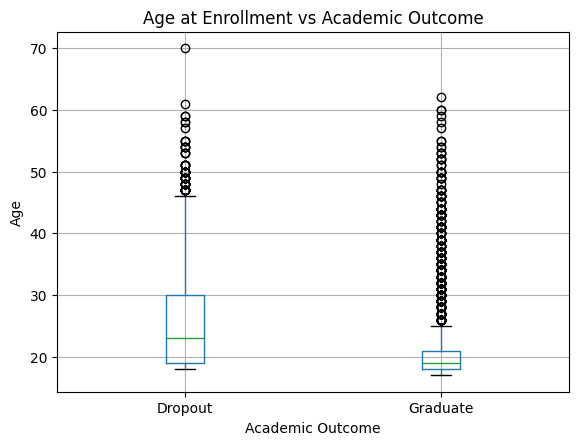

In [11]:
df.boxplot(
    column="age_at_enrollment",
    by="target"
)

plt.title("Age at Enrollment vs Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Age")
plt.show()

Admission grade vs target

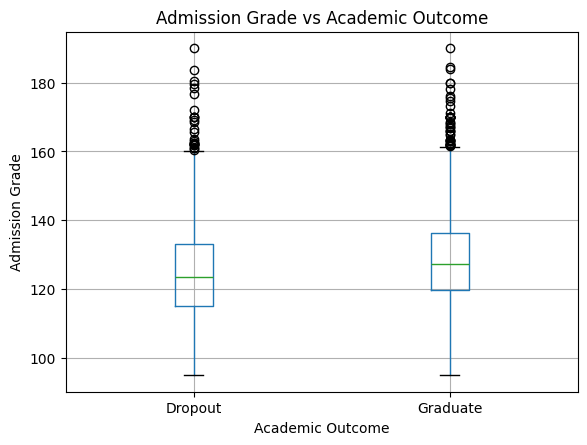

In [12]:
df.boxplot(
    column="admission_grade",
    by="target"
)

plt.title("Admission Grade vs Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Admission Grade")
plt.show()

Previous qualification grade vs target

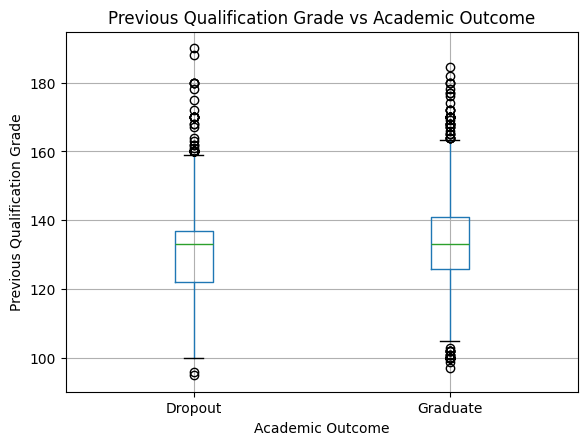

In [13]:
df.boxplot(
    column="previous_qualification_grade",
    by="target"
)

plt.title("Previous Qualification Grade vs Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Previous Qualification Grade")
plt.show()

First semester performance vs target

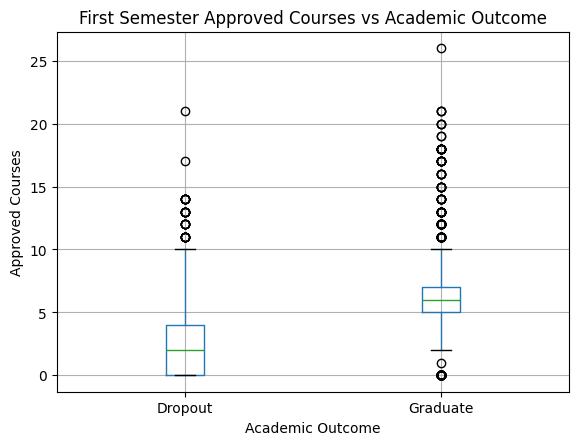

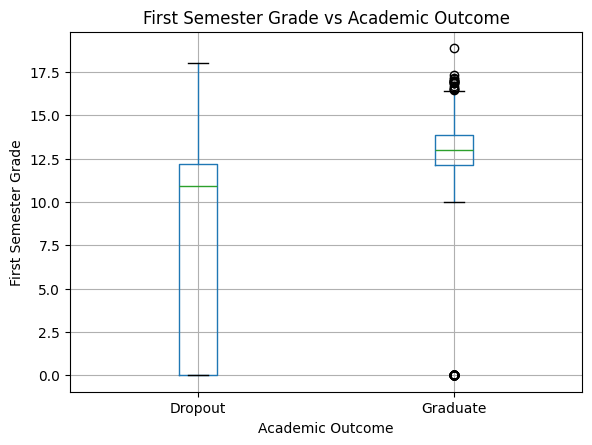

In [14]:
df.boxplot(
    column="curricular_units_1st_sem_approved",
    by="target"
)

plt.title("First Semester Approved Courses vs Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Approved Courses")
plt.show()

df.boxplot(
    column="curricular_units_1st_sem_grade",
    by="target"
)

plt.title("First Semester Grade vs Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("First Semester Grade")
plt.show()



Second semester performance vs target

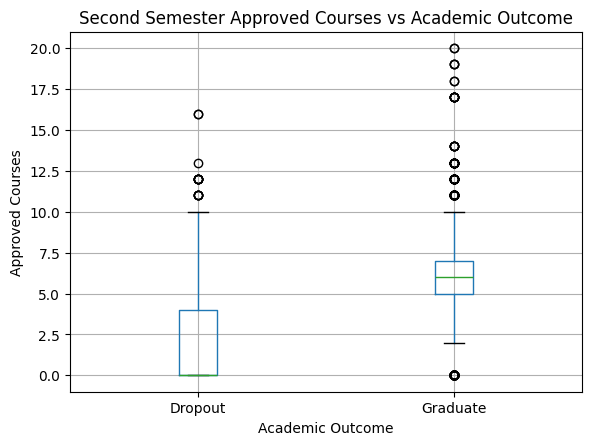

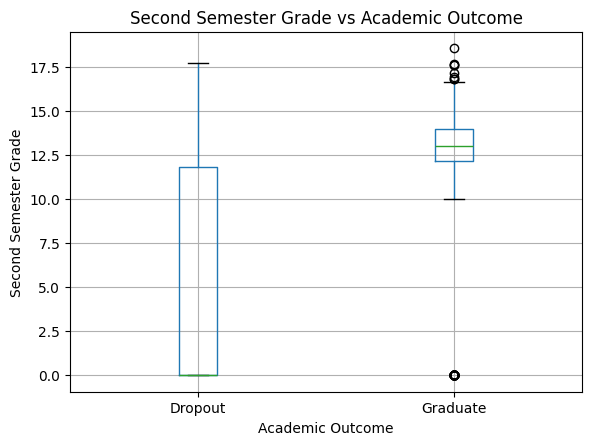

In [15]:
df.boxplot(
    column="curricular_units_2nd_sem_approved",
    by="target"
)

plt.title("Second Semester Approved Courses vs Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Approved Courses")
plt.show()


df.boxplot(
    column="curricular_units_2nd_sem_grade",
    by="target"
)

plt.title("Second Semester Grade vs Academic Outcome")
plt.suptitle("")
plt.xlabel("Academic Outcome")
plt.ylabel("Second Semester Grade")
plt.show()

Categorical EDA

Gender vs target

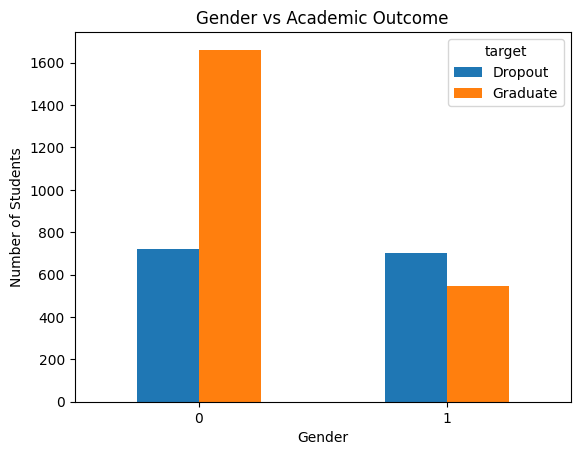

In [16]:
pd.crosstab(
    df["gender"],
    df["target"]
).plot(kind="bar")

plt.title("Gender vs Academic Outcome")
plt.xlabel("Gender")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.show()

Scholarship vs target

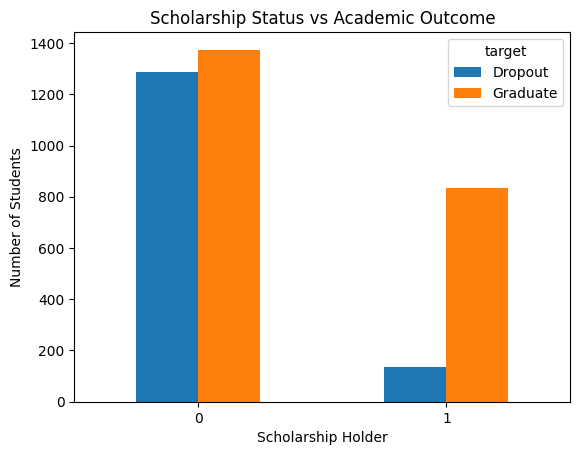

In [17]:
pd.crosstab(
    df["scholarship_holder"],
    df["target"]
).plot(kind="bar")

plt.title("Scholarship Status vs Academic Outcome")
plt.xlabel("Scholarship Holder")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.show()

Debtor vs target

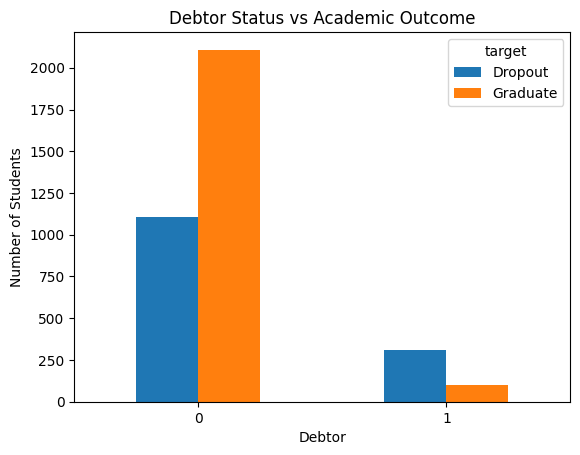

In [18]:
pd.crosstab(
    df["debtor"],
    df["target"]
).plot(kind="bar")

plt.title("Debtor Status vs Academic Outcome")
plt.xlabel("Debtor")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.show()

Tuition status vs target

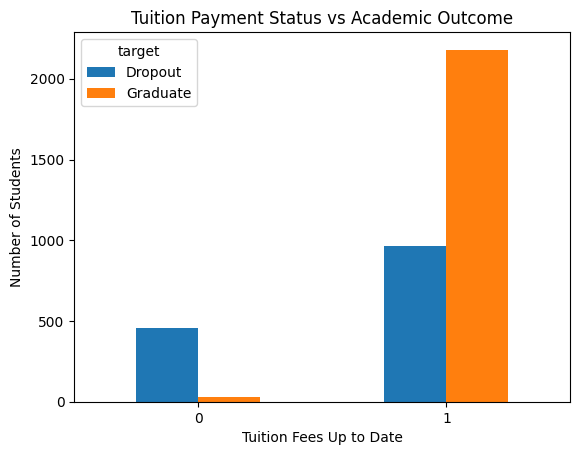

In [19]:
pd.crosstab(
    df["tuition_fees_up_to_date"],
    df["target"]
).plot(kind="bar")

plt.title("Tuition Payment Status vs Academic Outcome")
plt.xlabel("Tuition Fees Up to Date")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)

plt.show()

Correlation matrix

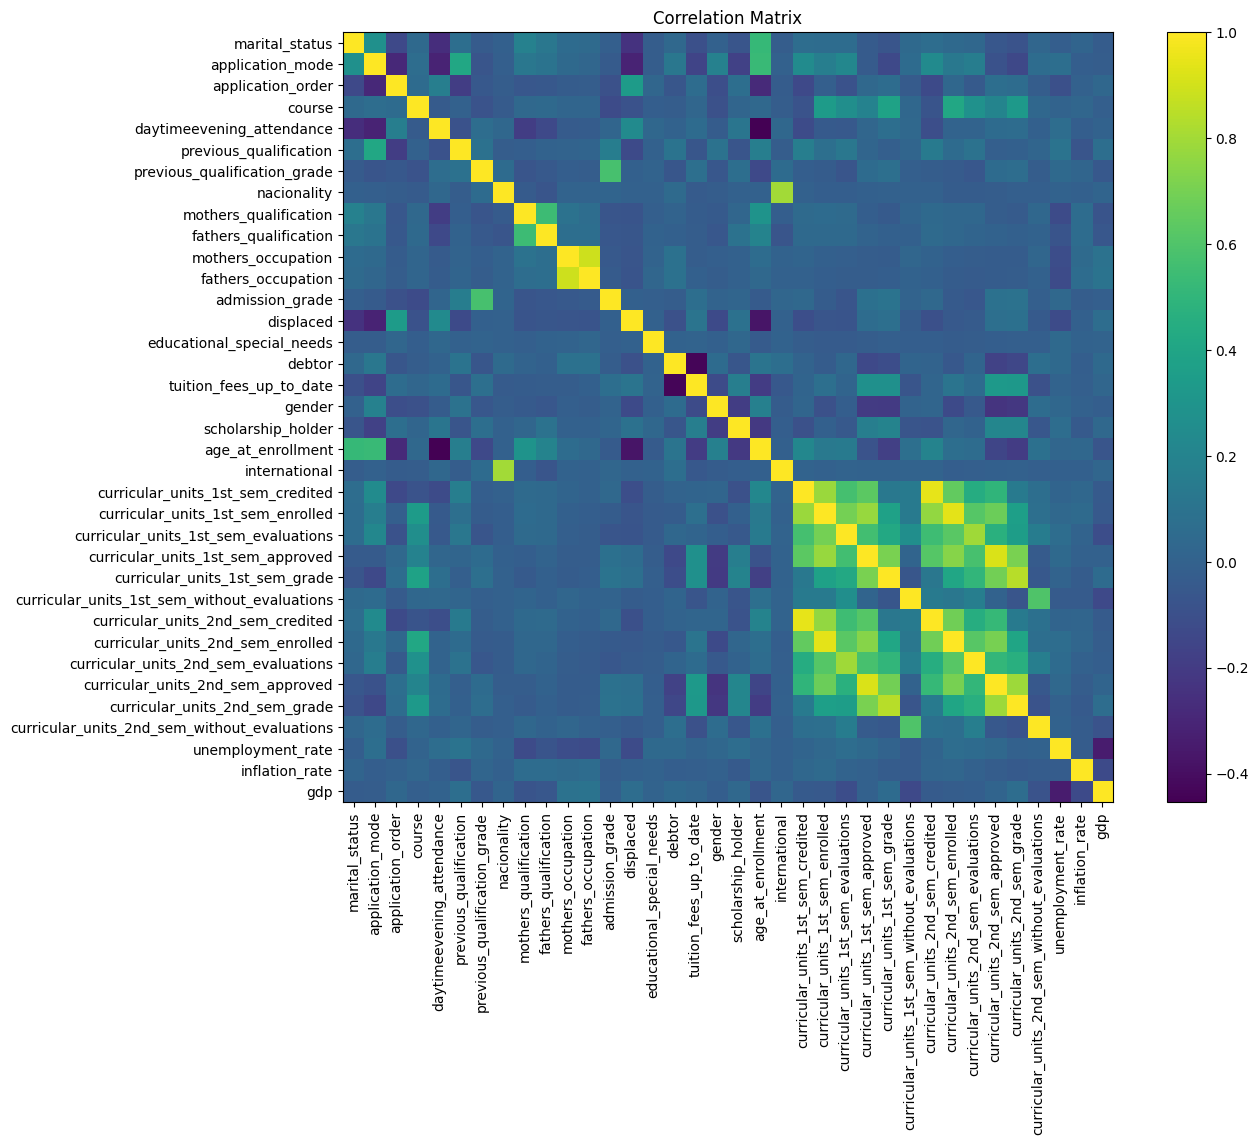

In [20]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

plt.imshow(correlation)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

plt.show()

strongest numerical relationships

In [21]:
correlation_pairs = correlation.unstack()

correlation_pairs = correlation_pairs[
    correlation_pairs != 1
]

print(
    correlation_pairs
    .abs()
    .sort_values(ascending=False)
    .head(20)
)

curricular_units_2nd_sem_credited     curricular_units_1st_sem_credited       0.947093
curricular_units_1st_sem_credited     curricular_units_2nd_sem_credited       0.947093
curricular_units_1st_sem_enrolled     curricular_units_2nd_sem_enrolled       0.941286
curricular_units_2nd_sem_enrolled     curricular_units_1st_sem_enrolled       0.941286
curricular_units_2nd_sem_approved     curricular_units_1st_sem_approved       0.916334
curricular_units_1st_sem_approved     curricular_units_2nd_sem_approved       0.916334
mothers_occupation                    fathers_occupation                      0.886568
fathers_occupation                    mothers_occupation                      0.886568
curricular_units_1st_sem_grade        curricular_units_2nd_sem_grade          0.845864
curricular_units_2nd_sem_grade        curricular_units_1st_sem_grade          0.845864
nacionality                           international                           0.797387
international                         nacio

** EDA Summary

The dataset contains 4,424 students and 37 columns. The target variable
contains three academic outcomes: Dropout, Enrolled, and Graduate.

The dataset was checked for missing values and duplicate records.
Numerical and categorical features were explored using statistical
summaries and visualizations.

Academic performance variables, admission information, financial
variables, and demographic characteristics were compared against the
target variable to identify potential relationships with student
outcomes.

The semester performance variables appear particularly important for
prediction. However, these variables must be considered carefully because
they become available after enrollment and may not be appropriate for a
model intended to predict dropout at the time of admission.

Therefore, the next preprocessing stage will separate early-available
features from later academic-performance features to reduce the risk of
data leakage. **

**Reasoning**:
Update the feature lists (`early_features`, `categorical_features`, `numerical_features`) to include all admission-time features and first-semester academic performance features, as per the subtask instructions.



In [22]:
early_features = [
    "marital_status",
    "application_mode",
    "application_order",
    "course",
    "daytimeevening_attendance",
    "previous_qualification",
    "previous_qualification_grade",
    "nacionality",
    "mothers_qualification",
    "fathers_qualification",
    "mothers_occupation",
    "fathers_occupation",
    "displaced",
    "educational_special_needs",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder",
    "international",
    "admission_grade",
    "age_at_enrollment",
    "curricular_units_1st_sem_credited",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_1st_sem_without_evaluations",
    "unemployment_rate",
    "inflation_rate",
    "gdp"
]

categorical_features = [
    "marital_status",
    "application_mode",
    "application_order",
    "course",
    "daytimeevening_attendance",
    "previous_qualification",
    "nacionality",
    "mothers_qualification",
    "fathers_qualification",
    "mothers_occupation",
    "fathers_occupation",
    "displaced",
    "educational_special_needs",
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder",
    "international"
]

numerical_features = [
    "previous_qualification_grade",
    "admission_grade",
    "age_at_enrollment",
    "curricular_units_1st_sem_credited",
    "curricular_units_1st_sem_enrolled",
    "curricular_units_1st_sem_evaluations",
    "curricular_units_1st_sem_approved",
    "curricular_units_1st_sem_grade",
    "curricular_units_1st_sem_without_evaluations",
    "unemployment_rate",
    "inflation_rate",
    "gdp"
]

print(f"Updated number of early features: {len(early_features)}")
print(f"Updated number of categorical features: {len(categorical_features)}")
print(f"Updated number of numerical features: {len(numerical_features)}")
print("No new features will be engineered at this stage.")

Updated number of early features: 30
Updated number of categorical features: 18
Updated number of numerical features: 12
No new features will be engineered at this stage.


## Update Data Preprocessing Pipeline

### Subtask:
Adjust the preprocessing pipeline to handle the expanded feature set. This includes updating the numerical and categorical feature lists for `StandardScaler` and `OneHotEncoder` respectively, and ensuring the `ColumnTransformer` is correctly configured.


**Reasoning**:
This step initializes the feature matrix `X_early` and the target vector `y` with the updated and comprehensive set of features, which is essential for the subsequent preprocessing steps.



In [23]:
X_early = df[early_features]
y = df["target"]

print("X_early shape:", X_early.shape)
print("y shape:", y.shape)

X_early shape: (3630, 30)
y shape: (3630,)


**Reasoning**:
Now that `X_early` and `y` are updated with the comprehensive feature set, the next step is to split the data into training and testing sets. This ensures that the preprocessing steps and subsequent model training are performed on correctly partitioned data.



In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_early,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (2904, 30)
Testing data: (726, 30)


**Reasoning**:
The `preprocessor` needs to be updated to reflect the new `numerical_features` and `categorical_features` lists defined in the previous subtask. This step re-initializes the `ColumnTransformer` with the correct feature sets for scaling and one-hot encoding.



In [25]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)
print("Preprocessor updated with new numerical and categorical features.")

Preprocessor updated with new numerical and categorical features.


**Reasoning**:
Apply the preprocessor to the training and testing data to transform the numerical and categorical features.



In [26]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (2904, 234)
X_test_processed shape: (726, 234)


## Implement Advanced Classification Models


Implement and evaluate additional advanced classification models such as Gradient Boosting (e.g., XGBoost, LightGBM) or Support Vector Machines (SVM) to potentially achieve higher accuracy.


In [27]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.svm import SVC

print("Advanced classification models imported successfully.")

Advanced classification models imported successfully.


**Reasoning**:
Now that the advanced classification models are imported, the next step is to define pipelines for each of these models (XGBoost, LightGBM, and SVM). This ensures that the preprocessing steps are consistently applied before classification.



In [28]:
from sklearn.pipeline import Pipeline

xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(random_state=42))
    ]
)

lightgbm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LGBMClassifier(random_state=42))
    ]
)

svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(random_state=42))
    ]
)

print("Advanced model pipelines created successfully.")

Advanced model pipelines created successfully.


**Reasoning**:
The target variable `y` needs to be encoded from categorical strings to numerical values (0, 1, 2) so that the XGBoost classifier can process it. `LabelEncoder` is the appropriate tool for this transformation.



In [29]:
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Fit and transform y_train, then transform y_test
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Target variable encoded successfully.")
print(f"Original y_train labels: {y_train.unique()}")
print(f"Encoded y_train labels: {np.sort(y_train_encoded)}")
print(f"Original y_test labels: {y_test.unique()}")
print(f"Encoded y_test labels: {np.sort(y_test_encoded)}")

# Now, fit the XGBoost model with the encoded target variable
xgboost_model.fit(X_train, y_train_encoded)
print("XGBoost model trained successfully with encoded target.")

Target variable encoded successfully.
Original y_train labels: ['Graduate' 'Dropout']
Encoded y_train labels: [0 0 0 ... 1 1 1]
Original y_test labels: ['Dropout' 'Graduate']
Encoded y_test labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1

**Reasoning**:
Train the LightGBM model using the preprocessed training data and the encoded target variable. This step fits the model to the features and target for LightGBM.



In [30]:
lightgbm_model.fit(X_train, y_train_encoded)
print("LightGBM model trained successfully.")

[LightGBM] [Info] Number of positive: 1767, number of negative: 1137
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002113 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 966
[LightGBM] [Info] Number of data points in the train set: 2904, number of used features: 114
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.608471 -> initscore=0.440890
[LightGBM] [Info] Start training from score 0.440890
LightGBM model trained successfully.


**Reasoning**:
Train the SVM model using the preprocessed training data and the encoded target variable.



In [31]:
svm_model.fit(X_train, y_train_encoded)
print("SVM model trained successfully.")

SVM model trained successfully.


## Hyperparameter Tuning and Cross-Validation


Perform systematic hyperparameter tuning for all chosen models using techniques like GridSearchCV or RandomizedSearchCV with cross-validation to find optimal parameters.


In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report
)

#  logistic_model to ensure it's in scope
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)) # Added random_state for reproducibility
    ]
)

# Define parameter grid for Logistic Regression
logistic_param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs'],
    'classifier__class_weight': [None, 'balanced']
}

#  GridSearchCV for Logistic Regression
grid_search_logistic = GridSearchCV(
    logistic_model,
    logistic_param_grid,
    cv=5,
    scoring='f1_weighted',
    verbose=1,
    n_jobs=-1
)

# Fit GridSearchCV
grid_search_logistic.fit(X_train, y_train_encoded)

print("Best parameters for Logistic Regression:", grid_search_logistic.best_params_)
print("Best F1-score for Logistic Regression:", grid_search_logistic.best_score_)

#  best Logistic Regression model evaluate korbo.
best_logistic_model = grid_search_logistic.best_estimator_
y_pred_logistic_tuned = best_logistic_model.predict(X_test)
# Calculate performance metrics
logistic_tuned_accuracy = accuracy_score(
    y_test_encoded,
    y_pred_logistic_tuned
)

logistic_tuned_f1 = f1_score(
    y_test_encoded,
    y_pred_logistic_tuned,
    average="weighted"
)

logistic_tuned_auc = roc_auc_score(
    y_test_encoded,
    y_pred_logistic_tuned
)

print("\nLOGISTIC (Tuned) Performance:")
print("=" * 50)

print(
    "Accuracy :",
    round(logistic_tuned_accuracy, 4)
)

print(
    "F1-Score :",
    round(logistic_tuned_f1, 4)
)

print(
    "ROC-AUC  :",
    round(logistic_tuned_auc, 4)
)

print("\nLOGISTIC REGRESSION (Tuned) Classification Report:")
print(classification_report(y_test_encoded, y_pred_logistic_tuned, target_names=label_encoder.classes_))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best parameters for Logistic Regression: {'classifier__C': 1, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Best F1-score for Logistic Regression: 0.8861426894820392

LOGISTIC (Tuned) Performance:
Accuracy : 0.8967
F1-Score : 0.8955
ROC-AUC  : 0.8818

LOGISTIC REGRESSION (Tuned) Classification Report:
              precision    recall  f1-score   support

     Dropout       0.91      0.81      0.86       284
    Graduate       0.89      0.95      0.92       442

    accuracy                           0.90       726
   macro avg       0.90      0.88      0.89       726
weighted avg       0.90      0.90      0.90       726



**Reasoning**:
Perform hyperparameter tuning for the Decision Tree model to find optimal parameters and evaluate its performance.



In [33]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Redefine decision_tree_model to ensure it's in scope
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]
)

# Define parameter grid for Decision Tree
decision_tree_param_grid = {
    'classifier__max_depth': [None, 5, 10, 20],
    'classifier__min_samples_leaf': [1, 5, 10],
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__class_weight': [None, 'balanced']
}

# Setup GridSearchCV for Decision Tree
grid_search_tree = GridSearchCV(
    decision_tree_model,
    decision_tree_param_grid,
    cv=5,
    scoring='f1_weighted',
    verbose=1,
    n_jobs=-1
)

# Fit GridSearchCV
grid_search_tree.fit(X_train, y_train_encoded)

print("Best parameters for Decision Tree:", grid_search_tree.best_params_)
print("Best F1-score for Decision Tree:", grid_search_tree.best_score_)

# Evaluate the best Decision Tree model
best_tree_model = grid_search_tree.best_estimator_
y_pred_tree_tuned = best_tree_model.predict(X_test)

# Calculate performance metrics
tree_tuned_accuracy = accuracy_score(
    y_test_encoded,
    y_pred_tree_tuned
)

tree_tuned_f1 = f1_score(
    y_test_encoded,
    y_pred_tree_tuned,
    average="weighted"
)

tree_tuned_auc = roc_auc_score(
    y_test_encoded,
    y_pred_tree_tuned
)

print("\nTREE (Tuned) Performance:")
print("=" * 50)

print(
    "Accuracy :",
    round(tree_tuned_accuracy, 4)
)

print(
    "F1-Score :",
    round(tree_tuned_f1, 4)
)

print(
    "ROC-AUC  :",
    round(tree_tuned_auc, 4)
)

print("\nDECISION TREE (Tuned) Classification Report:")
print(classification_report(y_test_encoded, y_pred_tree_tuned, target_names=label_encoder.classes_))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters for Decision Tree: {'classifier__class_weight': None, 'classifier__criterion': 'entropy', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10}
Best F1-score for Decision Tree: 0.8658537135883269

TREE (Tuned) Performance:
Accuracy : 0.8871
F1-Score : 0.8851
ROC-AUC  : 0.8682

DECISION TREE (Tuned) Classification Report:
              precision    recall  f1-score   support

     Dropout       0.92      0.78      0.84       284
    Graduate       0.87      0.95      0.91       442

    accuracy                           0.89       726
   macro avg       0.89      0.87      0.88       726
weighted avg       0.89      0.89      0.89       726



**Reasoning**:
Perform hyperparameter tuning for the Random Forest model using GridSearchCV to find optimal parameters and evaluate its performance.



In [34]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Redefine random_forest_model to ensure it's in scope
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(random_state=42))
    ]
)

# Define parameter grid for Random Forest
random_forest_param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_leaf': [1, 5, 10],
    'classifier__class_weight': [None, 'balanced']
}

# Setup GridSearchCV for Random Forest
grid_search_forest = GridSearchCV(
    random_forest_model,
    random_forest_param_grid,
    cv=5,
    scoring='f1_weighted',
    verbose=1,
    n_jobs=-1
)

# Fit GridSearchCV
grid_search_forest.fit(X_train, y_train_encoded)

print("Best parameters for Random Forest:", grid_search_forest.best_params_)
print("Best F1-score for Random Forest:", grid_search_forest.best_score_)

# Evaluate the best Random Forest model
best_forest_model = grid_search_forest.best_estimator_
y_pred_forest_tuned = best_forest_model.predict(X_test)

# Calculate performance metrics
forest_tuned_accuracy = accuracy_score(
    y_test_encoded,
    y_pred_forest_tuned
)

forest_tuned_f1 = f1_score(
    y_test_encoded,
    y_pred_forest_tuned,
    average="weighted"
)

forest_tuned_auc = roc_auc_score(
    y_test_encoded,
    y_pred_forest_tuned
)

print("\nFOREST (Tuned) Performance:")
print("=" * 50)

print(
    "Accuracy :",
    round(forest_tuned_accuracy, 4)
)

print(
    "F1-Score :",
    round(forest_tuned_f1, 4)
)

print(
    "ROC-AUC  :",
    round(forest_tuned_auc, 4)
)

print("\nRANDOM FOREST (Tuned) Classification Report:")
print(classification_report(y_test_encoded, y_pred_forest_tuned, target_names=label_encoder.classes_))


Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters for Random Forest: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 300}
Best F1-score for Random Forest: 0.8845682965226235

FOREST (Tuned) Performance:
Accuracy : 0.8871
F1-Score : 0.8849
ROC-AUC  : 0.867

RANDOM FOREST (Tuned) Classification Report:
              precision    recall  f1-score   support

     Dropout       0.92      0.77      0.84       284
    Graduate       0.87      0.96      0.91       442

    accuracy                           0.89       726
   macro avg       0.90      0.87      0.88       726
weighted avg       0.89      0.89      0.88       726



**Reasoning**:
Perform hyperparameter tuning for the XGBoost model to find optimal parameters and evaluate its performance.



In [35]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Redefine xgboost_model to ensure it's in scope
xgboost_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(random_state=42, eval_metric='mlogloss')) # Added eval_metric for multi-class
    ]
)

# Define parameter grid for XGBoost
xgb_param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__subsample': [0.7, 0.9, 1.0]
}

# Setup GridSearchCV for XGBoost
grid_search_xgb = GridSearchCV(
    xgboost_model,
    xgb_param_grid,
    cv=5,
    scoring='f1_weighted',
    verbose=1,
    n_jobs=-1
)

# Fit GridSearchCV
grid_search_xgb.fit(X_train, y_train_encoded)

print("Best parameters for XGBoost:", grid_search_xgb.best_params_)
print("Best F1-score for XGBoost:", grid_search_xgb.best_score_)

# Evaluate the best XGBoost model
best_xgb_model = grid_search_xgb.best_estimator_
y_pred_xgb_tuned = best_xgb_model.predict(X_test)
# Calculate performance metrics
xgb_tuned_accuracy = accuracy_score(
    y_test_encoded,
    y_pred_xgb_tuned
)

xgb_tuned_f1 = f1_score(
    y_test_encoded,
    y_pred_xgb_tuned,
    average="weighted"
)

xgb_tuned_auc = roc_auc_score(
    y_test_encoded,
    y_pred_xgb_tuned
)

print("\nXGB (Tuned) Performance:")
print("=" * 50)

print(
    "Accuracy :",
    round(xgb_tuned_accuracy, 4)
)

print(
    "F1-Score :",
    round(xgb_tuned_f1, 4)
)

print(
    "ROC-AUC  :",
    round(xgb_tuned_auc, 4)
)
print("\nXGBOOST (Tuned) Classification Report:")
print(classification_report(y_test_encoded, y_pred_xgb_tuned, target_names=label_encoder.classes_))

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Best parameters for XGBoost: {'classifier__learning_rate': 0.2, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 1.0}
Best F1-score for XGBoost: 0.8899395607397226

XGB (Tuned) Performance:
Accuracy : 0.905
F1-Score : 0.9035
ROC-AUC  : 0.888

XGBOOST (Tuned) Classification Report:
              precision    recall  f1-score   support

     Dropout       0.94      0.81      0.87       284
    Graduate       0.89      0.97      0.93       442

    accuracy                           0.90       726
   macro avg       0.91      0.89      0.90       726
weighted avg       0.91      0.90      0.90       726



In [36]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Redefine SVM model to ensure it's in scope
svm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(
            random_state=42
        ))
    ]
)

# Define parameter grid for SVM
svm_param_grid = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__kernel": ["linear", "rbf"],
    "classifier__gamma": ["scale", "auto"],
    "classifier__class_weight": [None, "balanced"]
}

# Setup GridSearchCV for SVM
grid_search_svm = GridSearchCV(
    svm_model,
    svm_param_grid,
    cv=5,
    scoring="f1_weighted",
    verbose=1,
    n_jobs=-1
)

# Fit GridSearchCV
grid_search_svm.fit(X_train, y_train_encoded)

print("Best parameters for SVM:", grid_search_svm.best_params_)
print("Best F1-score for SVM:", grid_search_svm.best_score_)

# Evaluate the best SVM model
best_svm_model = grid_search_svm.best_estimator_

y_pred_svm_tuned = best_svm_model.predict(X_test)

# Probability of the positive class for ROC-AUC
y_prob_svm_tuned = best_svm_model.decision_function(X_test)

# Calculate performance metrics
svm_tuned_accuracy = accuracy_score(
    y_test_encoded,
    y_pred_svm_tuned
)

svm_tuned_f1 = f1_score(
    y_test_encoded,
    y_pred_svm_tuned,
    average="weighted"
)

svm_tuned_auc = roc_auc_score(
    y_test_encoded,
    y_prob_svm_tuned
)

print("\nSVM (Tuned) Performance:")
print("=" * 50)

print(
    "Accuracy :",
    round(svm_tuned_accuracy, 4)
)

print(
    "F1-Score :",
    round(svm_tuned_f1, 4)
)

print(
    "ROC-AUC  :",
    round(svm_tuned_auc, 4)
)

print("\nSVM (Tuned) Classification Report:")
print(
    classification_report(
        y_test_encoded,
        y_pred_svm_tuned,
        target_names=label_encoder.classes_
    )
)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best parameters for SVM: {'classifier__C': 10, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}
Best F1-score for SVM: 0.8885498723051954

SVM (Tuned) Performance:
Accuracy : 0.8994
F1-Score : 0.8989
ROC-AUC  : 0.9476

SVM (Tuned) Classification Report:
              precision    recall  f1-score   support

     Dropout       0.89      0.85      0.87       284
    Graduate       0.90      0.93      0.92       442

    accuracy                           0.90       726
   macro avg       0.90      0.89      0.89       726
weighted avg       0.90      0.90      0.90       726



In [37]:
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Create a separate preprocessor for MLP
# sparse_output=False makes the encoded data dense for MLP
mlp_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

# Redefine MLP model to ensure it's in scope
mlp_model = Pipeline(
    steps=[
        ("preprocessor", mlp_preprocessor),
        (
            "classifier",
            MLPClassifier(
                max_iter=500,
                early_stopping=True,
                random_state=42
            )
        )
    ]
)

# Define parameter grid for MLP
mlp_param_grid = {
    "classifier__hidden_layer_sizes": [
        (32,),
        (64,),
        (64, 32),
        (128, 64)
    ],
    "classifier__activation": [
        "relu",
        "tanh"
    ],
    "classifier__learning_rate": [
        "constant",
        "adaptive"
    ],
    "classifier__alpha": [
        0.0001,
        0.001,
        0.01
    ]
}

# Setup GridSearchCV for MLP
grid_search_mlp = GridSearchCV(
    mlp_model,
    mlp_param_grid,
    cv=5,
    scoring="f1_weighted",
    verbose=1,
    n_jobs=-1
)

# Fit GridSearchCV
grid_search_mlp.fit(
    X_train,
    y_train_encoded
)

print(
    "Best parameters for MLP:",
    grid_search_mlp.best_params_
)

print(
    "Best F1-score for MLP:",
    grid_search_mlp.best_score_
)

# Evaluate the best MLP model
best_mlp_model = grid_search_mlp.best_estimator_

y_pred_mlp_tuned = best_mlp_model.predict(X_test)

# Probability of the positive class for ROC-AUC
y_prob_mlp_tuned = best_mlp_model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
mlp_tuned_accuracy = accuracy_score(
    y_test_encoded,
    y_pred_mlp_tuned
)

mlp_tuned_f1 = f1_score(
    y_test_encoded,
    y_pred_mlp_tuned,
    average="weighted"
)

mlp_tuned_auc = roc_auc_score(
    y_test_encoded,
    y_prob_mlp_tuned
)

print("\nMLP (Tuned) Performance:")
print("=" * 50)

print(
    "Accuracy :",
    round(mlp_tuned_accuracy, 4)
)

print(
    "F1-Score :",
    round(mlp_tuned_f1, 4)
)

print(
    "ROC-AUC  :",
    round(mlp_tuned_auc, 4)
)

print("\nMLP (Tuned) Classification Report:")

print(
    classification_report(
        y_test_encoded,
        y_pred_mlp_tuned,
        target_names=label_encoder.classes_
    )
)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best parameters for MLP: {'classifier__activation': 'tanh', 'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (128, 64), 'classifier__learning_rate': 'constant'}
Best F1-score for MLP: 0.8826005175049259

MLP (Tuned) Performance:
Accuracy : 0.8829
F1-Score : 0.8823
ROC-AUC  : 0.926

MLP (Tuned) Classification Report:
              precision    recall  f1-score   support

     Dropout       0.87      0.82      0.85       284
    Graduate       0.89      0.92      0.91       442

    accuracy                           0.88       726
   macro avg       0.88      0.87      0.88       726
weighted avg       0.88      0.88      0.88       726



In [38]:
from sklearn.metrics import precision_score, recall_score

model_predictions = {
    "Logistic Regression": y_pred_logistic_tuned,
    "Decision Tree": y_pred_tree_tuned,
    "Random Forest": y_pred_forest_tuned,
    "XGBoost": y_pred_xgb_tuned,
    "SVM": y_pred_svm_tuned,
    "MLP": y_pred_mlp_tuned,
}

results = []
for model_name, y_pred in model_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_encoded, y_pred),
        "Precision": precision_score(y_test_encoded, y_pred, average="weighted"),
        "Recall": recall_score(y_test_encoded, y_pred, average="weighted"),
        "F1-Score": f1_score(y_test_encoded, y_pred, average="weighted"),
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.896694,0.897766,0.896694,0.895462
1,Decision Tree,0.887052,0.889682,0.887052,0.885104
2,Random Forest,0.887052,0.890570,0.887052,0.884869
3,XGBoost,0.904959,0.907701,0.904959,0.903463
4,SVM,0.899449,0.899211,0.899449,0.898924
5,MLP,0.882920,0.882492,0.882920,0.882309


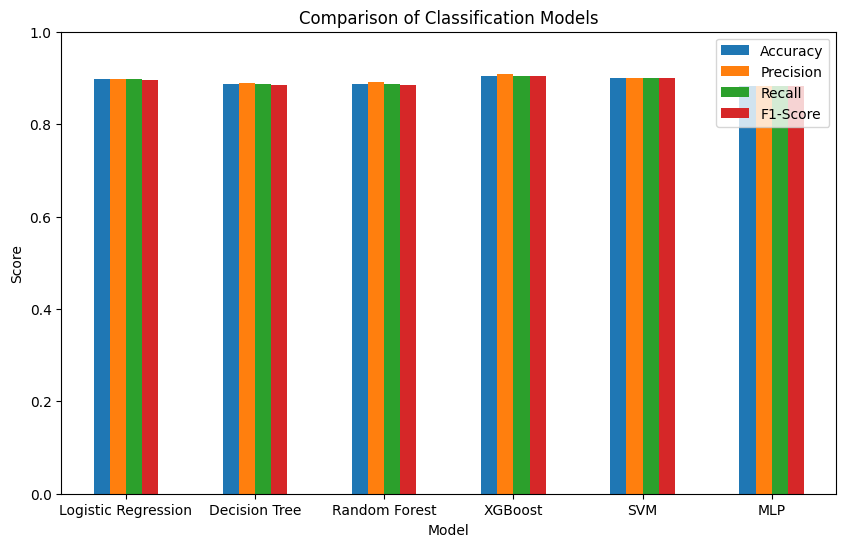

In [39]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

Confusion matrices for all models

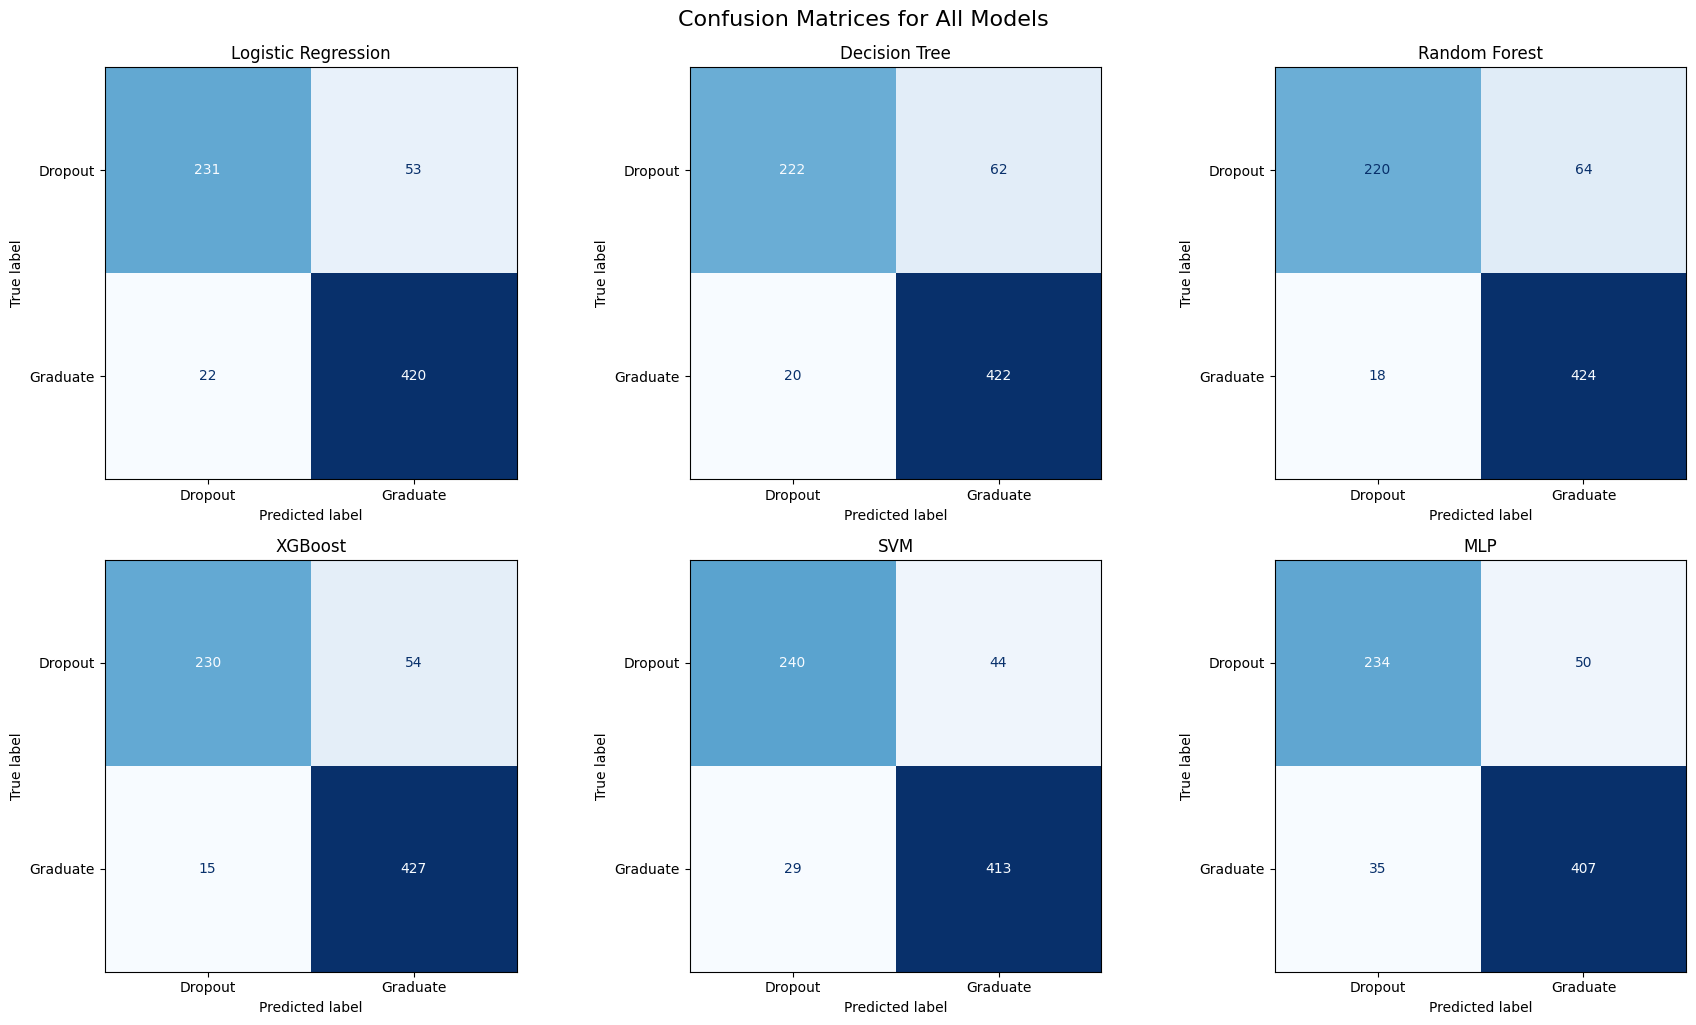

In [40]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (model_name, y_pred) in zip(axes, model_predictions.items()):
    cm = confusion_matrix(y_test_encoded, y_pred)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
    )
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(model_name)

plt.tight_layout()
plt.suptitle("Confusion Matrices for All Models", y=1.02, fontsize=16)
plt.show()
